# Verificação da Cadeia de Sinal: T_antena, fluxos e unidades

Este notebook verifica, com um exemplo mínimo, a determinação da **temperatura
de antena** $T_A$ e dos **fluxos** $S$ para os três tipos de fonte suportados
pelo pipeline do RadioSkySim:

1. **Satélite GNSS** — potência emitida / EIRP + *free space path loss*;
2. **Sol (fonte local)** — fluxo Learmonth (SRD/SRS), média em janela temporal;
3. **Radiofonte** — fluxo de catálogo com modelo espectral em lei de potência.

O objetivo é comparar **unidades**, **S** e **T** e confrontar a implementação
do `TODSimulator` com a expressão física de referência (radioastronomia padrão).

> **Contexto (2026-08-15):** esta verificação encontrou e motivou a correção de
> um bug no `TODSimulator` — a fórmula de $T_A$ **não aplicava o fator
> $1/(2\Omega)$** (ângulo sólido do feixe / diretividade), subestimando $T_A$ em
> ~20× para o feixe BINGO. As células abaixo mostram a física de referência e
> **confirmam que a implementação corrigida agora reproduz o valor esperado**.


## Racional físico

**Diretividade** (feixe com padrão de potência $B_n(\theta,\phi)$ normalizado
para pico = 1):

$$
D(\theta,\phi)=\frac{4\pi\,B_n(\theta,\phi)}{\iint B_n\,d\Omega},\qquad
D_0=\frac{4\pi}{\Omega},\qquad \Omega=\iint B_n(\theta,\phi)\,d\Omega
$$

com $\Omega$ o **ângulo sólido do feixe** (sr).

**Fonte pontual** (área efetiva $A_e=\lambda^2 D/(4\pi)=\lambda^2 B_n/\Omega$):

$$
T_A[\mathrm{K}] = \frac{1}{2k_B}\,A_e\,S_\nu
                = 10^{-26}\,\frac{\lambda^2}{2\,k_B\,\Omega}\,
                  S_\nu[\mathrm{Jy}]\,B_n(\hat\theta,\hat\phi)
$$

onde $S_\nu$ em Jy e $10^{-26}$ converte Jy $\to$ W/m²/Hz. O fator $1/2$
corresponde a **uma polarização** (fonte não polarizada). Para duas
polarizações, remove-se o $1/2$ (fica $T_A = S\,\lambda^2 B_n/(k_B\,\Omega)$).

**Determinação do fluxo $S$ por tipo de fonte:**

| Fonte | Como obter $S_\nu$ |
|---|---|
| GNSS | PSD = EIRP $\times$ shape; $S_\mathrm{obs}=\mathrm{PSD}/(4\pi r^2)$ (path loss), $r$ = distância |
| Sol | Dados Learmonth (SFU), média em janela (15 min – 1 h), SFU→Jy (×$10^4$) |
| Radiofonte | Catálogo: $S(\nu)=S_0(\nu/\nu_0)^{-\alpha}$ em Jy |

**Convenções do projeto (AGENTS.md):** frequência em MHz (usuário) / Hz
(interno); ângulos em graus (usuário) / radianos (interno); $T_A$ em Kelvin.

In [27]:
"""Setup: caminho do projeto, imports e constantes físicas."""

from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

# ── Detecta a raiz do projeto e adiciona src/ ao path ──
cwd = Path.cwd().resolve()
project_root = next(
    (
        p
        for p in [cwd, *cwd.parents]
        if (p / "src" / "radioskysims").exists() and (p / "settings.toml").exists()
    ),
    None,
)
if project_root is None:
    raise RuntimeError("Raiz do projeto não encontrada.")
src_path = str((project_root / "src").resolve())
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# ── Constantes físicas (SI) ──
from scipy.constants import c, k as k_B  # m/s ; J/K

JY_TO_WM2HZ = 1e-26   # 1 Jy = 1e-26 W/m²/Hz
SFU_TO_JY = 1e4       # 1 SFU = 1e4 Jy (fluxo solar)

# ── Feixe BINGO (horn01) ──
BEAM_CSV = project_root / "src/radioskysims/resources/beams/beampattern_horn01.csv"
POL = "V_COPOL"       # polarização de referência
SOLAR_CACHE = (
    project_root
    / "data/aux/signals/solar_flux/solar_flux_20250509T030000_20250510T030000.nc"
)

plt.rcParams["figure.dpi"] = 110
print(f"projeto: {project_root}")
print(f"beam:    {BEAM_CSV.name} | existe: {BEAM_CSV.exists()}")
print(f"fluxo solar em cache: {SOLAR_CACHE.exists()}")

projeto: /home/lbarosi/RadioSkySim
beam:    beampattern_horn01.csv | existe: True
fluxo solar em cache: True


In [38]:
"""Carrega o feixe BINGO e define B_n(θ,f), Ω(f) e as propriedades.

Ω(f) é calculado por INTEGRAÇÃO do padrão de potência interpolado em
frequência. A versão anterior usava a frequência mais próxima do grid do
beam (searchsorted), o que produzia DEGRAUS — a origem das descontinuidades
em TA_sun/TA_radio.
"""

df = pd.read_csv(BEAM_CSV)
a_pos = np.sort(df[df["angle"] >= 0]["angle"].unique())
freqs_mhz = np.sort(df["frequency"].unique())
pols = sorted(df["polarization"].unique())

# Padrão de potência (pico=1) por polarização: shape (n_angle, n_freq)
power = {}
for pol in pols:
    piv = (
        df[df["polarization"] == pol]
        .pivot_table(index="angle", columns="frequency", values="amplitude", aggfunc="mean")
        .reindex(a_pos)
        .interpolate(limit_direction="both")
    )
    P = piv.to_numpy(dtype=float) ** 2
    power[pol] = P / P.max()

from scipy.interpolate import RegularGridInterpolator

INTERP = {
    pol: RegularGridInterpolator((a_pos, freqs_mhz), power[pol], bounds_error=False, fill_value=0.0)
    for pol in pols
}


def B_n(theta_deg, f_mhz, pol=POL):
    """Padrão de potência normalizado (pico=1), interp bilinear. θ em graus."""
    th = np.abs(np.atleast_1d(np.asarray(theta_deg, dtype=float)))
    fv = np.atleast_1d(np.asarray(f_mhz, dtype=float))
    pts = np.stack(np.meshgrid(th, fv, indexing="ij"), axis=-1)
    out = INTERP[pol](pts)
    if np.ndim(theta_deg) == 0 and np.ndim(f_mhz) == 0:
        return float(out[0, 0])
    if np.ndim(theta_deg) == 0:
        return out[0]
    return out


def Omega(f_mhz, pol=POL):
    """Ângulo sólido Ω(f) = 2π∫₀^π B_n(θ,f) sinθ dθ (interp em frequência)."""
    th = np.deg2rad(a_pos)
    dth = np.gradient(th)
    fv = np.atleast_1d(np.asarray(f_mhz, dtype=float))
    out = np.empty_like(fv, dtype=float)
    for j, f in enumerate(fv):
        Pcol = INTERP[pol](np.stack([a_pos, np.full_like(a_pos, f)], axis=-1))
        out[j] = 2.0 * np.pi * np.sum(Pcol * np.sin(th) * dth)
    return out[0] if len(fv) == 1 else out


# ── Propriedades por frequência (grid nativo do beam) ──
f_mhz = freqs_mhz
Om = Omega(f_mhz, POL)
D0 = 4.0 * np.pi / Om
lam = c / (f_mhz * 1e6)
Ae0 = lam**2 / Om
K_per_Jy = JY_TO_WM2HZ * lam**2 / (2.0 * k_B * Om)   # K/Jy (1 polarização)

print("Frequência | Ω (sr) | D0 (dBi) | K/Jy (mK)")
print("-" * 52)
for i, f in enumerate(f_mhz):
    if f % 100 == 0 or f == 1175.0:
        print(f"{f:8.0f} MHz | {Om[i]:.4e} | {10*np.log10(D0[i]):6.2f} | {K_per_Jy[i]*1e3:8.3f}")

Frequência | Ω (sr) | D0 (dBi) | K/Jy (mK)
----------------------------------------------------
     900 MHz | 4.5177e-02 |  24.44 |    0.889
    1000 MHz | 3.4835e-02 |  25.57 |    0.934
    1100 MHz | 3.0627e-02 |  26.13 |    0.878
    1175 MHz | 2.5330e-02 |  26.96 |    0.931
    1200 MHz | 2.4407e-02 |  27.12 |    0.926
    1300 MHz | 2.0082e-02 |  27.96 |    0.959


In [39]:
"""Funções físicas centrais: T_A de fonte pontual (fórmula de referência) e a
fórmula ANTIGA do TODSimulator (pré-correção, mantida só para comparação)."""


def T_antenna_point(S_jy, f_hz, theta_deg=0.0, pol=POL, n_pol=1):
    """T_A [K] de fonte pontual (referência, radioastronomia padrão).

    T_A = S[Jy]·1e-26 · λ² · B_n(θ) / (2 k_B Ω)   →  n_pol = 1 (padrão)
    T_A = S[Jy]·1e-26 · λ² · B_n(θ) / (k_B Ω)     →  n_pol = 2
    """
    S = np.asarray(S_jy, dtype=float) * JY_TO_WM2HZ
    fv = np.asarray(f_hz, dtype=float)
    lam2 = (c / fv) ** 2
    Bn = np.asarray(B_n(theta_deg, fv * 1e-6, pol), dtype=float)
    Om = np.asarray(Omega(fv * 1e-6, pol), dtype=float)
    denom = 2.0 * k_B * Om if n_pol == 1 else k_B * Om
    return S * lam2 * Bn / denom


def T_antenna_old(S_wm2hz, f_hz, theta_deg=0.0, gain=1.0, pol=POL):
    """Fórmula ANTIGA (bug): T = gain·B_n·S·λ²/k_B — sem o fator 1/(2Ω)."""
    S = np.asarray(S_wm2hz, dtype=float)
    fv = np.asarray(f_hz, dtype=float)
    lam2 = (c / fv) ** 2
    Bn = np.asarray(B_n(theta_deg, fv * 1e-6, pol), dtype=float)
    return gain * Bn * S * lam2 / k_B


# ── Verificação do fator que faltava: 1/(2Ω) ──
f_test = 1175.0e6
Om_test = float(Omega(1175.0))
TA_ref = T_antenna_point([1.0], [f_test])[0]                # 1 Jy on-axis
TA_old = T_antenna_old([1e-26], [f_test])[0]                # 1 Jy on-axis (antigo)
print(f"Ω(1175 MHz) = {Om_test:.4e} sr  →  2Ω = {2*Om_test:.4f}")
print(f"1 Jy on-axis @1175 MHz:")
print(f"  T_A referência (1 pol) = {TA_ref:.4e} K  ({TA_ref*1e3:.3f} mK)")
print(f"  T_A fórmula antiga     = {TA_old:.4e} K  ({TA_old*1e3:.4f} mK)")

Ω(1175 MHz) = 2.5330e-02 sr  →  2Ω = 0.0507
1 Jy on-axis @1175 MHz:
  T_A referência (1 pol) = 9.1753e-04 K  (0.918 mK)
  T_A fórmula antiga     = 4.6482e-05 K  (0.0465 mK)


In [40]:
print(f"Diretividade média na banda: {np.mean(10*np.log10(D0)):.1f} dBi")
print("(BeamProperties.directivity agora calcula a diretividade física D0 = 4πPmax/Ω)")

Diretividade média na banda: 26.4 dBi
(BeamProperties.directivity agora calcula a diretividade física D0 = 4πPmax/Ω)


## 1) Satélite GNSS

Física: o satélite transmite com potência espectral $\mathrm{PSD}(f)$ [W/Hz]
determinada pelo **EIRP** e pelo formato do espectro (modulação). No observador,
a densidade de fluxo é obtida pela diluição isotrópica (free-space path loss):

$$
S_\mathrm{obs}(f) = \frac{\mathrm{PSD}(f)}{4\pi\,r^2}\ [\mathrm{W/m^2/Hz}]
\quad\longrightarrow\quad
S_\nu[\mathrm{Jy}] = S_\mathrm{obs}\times 10^{26}
$$

Exemplo: **GPS L5** (1176.45 MHz, BPSK(10), EIRP 24.6 dBW — valor do
`sat_signals.json` do projeto) a uma distância típica $r=2.0\times10^7$ m.
O espectro BPSK é modelado por $S(f)=EIRP\,\mathrm{sinc}^2((f-f_c)/R_c)/(2R_c)$.

=== SATÉLITE (GPS L5, EIRP = 24.6 dBW, r = 2.0e+07 m) ===
EIRP      =   288.40 W
S_obs,pep= 2.786e-21 W/m²/Hz
S_pep    = 2.786e+05 Jy  (@1176.00 MHz)
T_A,pep  =    255.4 K   (fórmula antiga: 12.9 K)


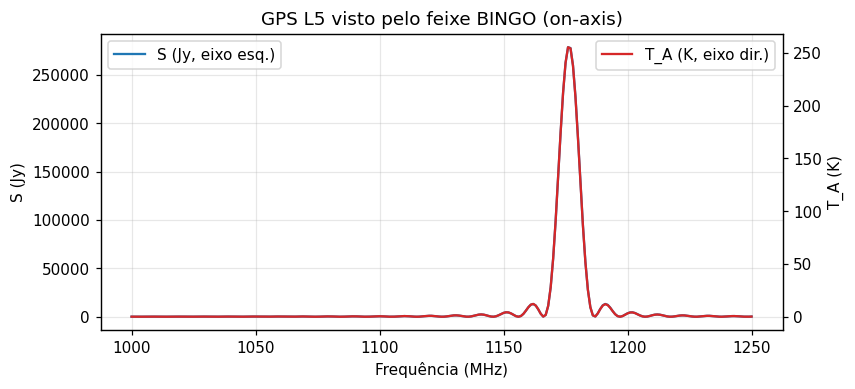

In [41]:
"""Satélite GNSS: PSD → fluxo no observador → S (Jy) → T_A on-axis."""

fc_hz = 1176.45e6          # GPS L5
Rc = 10.23e6               # chip rate BPSK(10) (Hz)
EIRP_dBW = 24.6
EIRP_W = 10.0 ** (EIRP_dBW / 10.0)
r_sat = 2.0e7              # distância típica GPS (m)

f_mhz = np.linspace(1000, 1250, 251)
f_hz = f_mhz * 1e6


def sinc(x):
    return np.where(x == 0, 1.0, np.sin(np.pi * x) / (np.pi * x))


# PSD de potência total transmitida (W/Hz), normalizada: ∫PSD df = EIRP
shape = (1.0 / (2.0 * Rc)) * sinc((f_hz - fc_hz) / Rc) ** 2
PSD = EIRP_W * shape                       # W/Hz

# Fluxo no observador
S_obs = PSD / (4.0 * np.pi * r_sat**2)     # W/m²/Hz
S_jy = S_obs / JY_TO_WM2HZ                 # Jy

# T_A on-axis (fórmula de referência, 1 polarização)
TA_sat = T_antenna_point(S_jy, f_hz)

i = int(np.argmin(np.abs(f_mhz - fc_hz / 1e6)))
print("=== SATÉLITE (GPS L5, EIRP = %.1f dBW, r = %.1e m) ===" % (EIRP_dBW, r_sat))
print(f"EIRP      = {EIRP_W:8.2f} W")
print(f"S_obs,pep= {S_obs.max():8.3e} W/m²/Hz")
print(f"S_pep    = {S_jy.max():8.3e} Jy  (@{f_mhz[np.argmax(S_jy)]:.2f} MHz)")
print(f"T_A,pep  = {TA_sat.max():8.1f} K   (fórmula antiga: {TA_sat.max()*2*Om_test:.1f} K)")

# Off-axis: T_A cai com B_n(θ)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(f_mhz, S_jy, label="S (Jy, eixo esq.)")
ax.set_xlabel("Frequência (MHz)"); ax.set_ylabel("S (Jy)")
ax2 = ax.twinx()
ax2.plot(f_mhz, TA_sat, color="C3", label="T_A (K, eixo dir.)")
ax2.set_ylabel("T_A (K)")
ax.set_title("GPS L5 visto pelo feixe BINGO (on-axis)")
ax.legend(loc="upper left"); ax2.legend(loc="upper right"); ax.grid(alpha=0.3)
plt.show()

## 2) Sol (fonte local)

Física: fluxo do observatório de **Learmonth** (SRD/SRS), originalmente em
**SFU**, convertido para **Jy** ($1\,\mathrm{SFU}=10^4\,\mathrm{Jy}$). Seguindo
a rationale, o fluxo representativo é a **média numa janela temporal de
15 min – 1 h** (aqui: mediana em janela de 1 h em torno do trânsito), e a
interpolação fornece os valores nas frequências da simulação.

$$
S_\nu[\mathrm{Jy}] = \overline{S}_{\mathrm{janela}}[SFU]\times 10^4
\quad\longrightarrow\quad
S_\nu[\mathrm{W/m^2/Hz}] = S_\nu[\mathrm{Jy}]\times 10^{-26}
$$

Usa-se o cache local `solar_flux_20250509...nc` (há fallback para um modelo
quiet-Sun caso o arquivo não exista).

Fluxo solar (mediana 1h, Jy) por frequência SRD:
     245 MHz:  3.50e+06 Jy
     410 MHz:  3.70e+05 Jy
     610 MHz:  6.20e+05 Jy
    1415 MHz:  9.80e+05 Jy
    2695 MHz:  1.46e+06 Jy
    4995 MHz:  2.09e+06 Jy
    8800 MHz:  2.94e+06 Jy
   15400 MHz:  5.14e+06 Jy
=== SOL (fonte: Learmonth (cache SRD/SRS)) ===
S(1175 MHz) =  8.86e+05 Jy
S(1175 MHz) =  8.86e-21 W/m²/Hz
T_A(1175)   =    812.7 K   (fórmula antiga: 41.2 K)


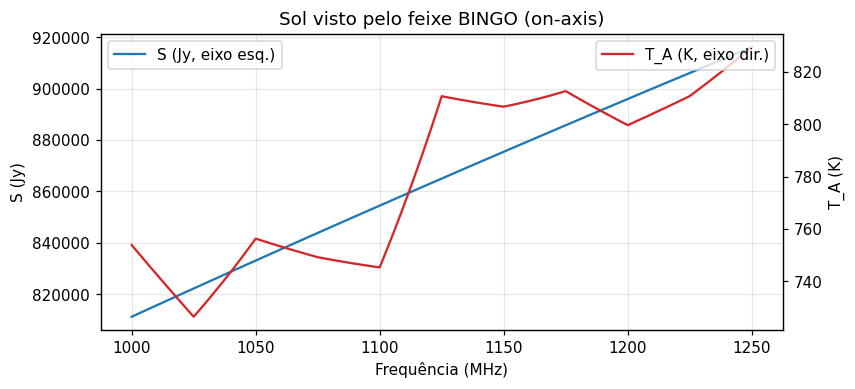

In [42]:
"""Sol: fluxo Learmonth (SFU→Jy), média em janela temporal, interpolação e T_A."""

# ── Fluxo representativo por frequência (Jy) ──
if SOLAR_CACHE.exists():
    ds_sun = xr.open_dataset(SOLAR_CACHE)
    flux = ds_sun["flux_jy"]                       # (time, frequency_mhz)
    f_sun = flux.frequency_mhz.values.astype(float)

    def _window_median(freq_sel, window_min=10.0):
        col = flux.sel(frequency_mhz=freq_sel).values
        t = flux.time.values
        dt_min = np.median(np.diff(t.astype("datetime64[s]").astype(float))) / 60.0
        k_peak = int(np.nanargmax(np.nan_to_num(col, nan=0.0)))
        nw = max(1, int(round(window_min / dt_min)))
        lo = max(0, k_peak - nw // 2)
        hi = min(len(col), lo + nw)
        if hi - lo < nw:
            lo = max(0, hi - nw)
        return float(np.nanmedian(col[lo:hi]))

    # Valores representativos (mediana em janela de 1h) nas frequências SRD
    vals = np.array([_window_median(f, 1.0) for f in f_sun])
    print("Fluxo solar (mediana 1h, Jy) por frequência SRD:")
    for f, v in zip(f_sun, vals, strict=False):
        print(f"  {f:6.0f} MHz: {v:9.2e} Jy")

    # Interpolação log-log entre 610 e 1415 MHz (banda BINGO está entre eles)
    mask = (f_sun >= 610) & (f_sun <= 1415)
    fi, vi = f_sun[mask], vals[mask]
    S_sun_jy = np.exp(np.interp(np.log(f_mhz), np.log(fi), np.log(vi)))
    src = "Learmonth (cache SRD/SRS)"
else:
    # Fallback: modelo quiet-Sun (sem rede / sem cache)
    S_sun_jy = 6.0e5 * (f_mhz / 1000.0) ** 0.3   # ~6e5 Jy @1 GHz, cresce c/ ν
    src = "modelo quiet-Sun (fallback)"

S_sun_wm2hz = S_sun_jy * JY_TO_WM2HZ
TA_sun = T_antenna_point(S_sun_jy, f_hz)

print("=== SOL (fonte: %s) ===" % src)
print(f"S(1175 MHz) = {np.interp(1175.0, f_mhz, S_sun_jy):9.2e} Jy")
print(f"S(1175 MHz) = {np.interp(1175.0, f_mhz, S_sun_wm2hz):9.2e} W/m²/Hz")
print(f"T_A(1175)   = {np.interp(1175.0, f_mhz, TA_sun):8.1f} K   (fórmula antiga: {np.interp(1175.0, f_mhz, TA_sun)*2*Om_test:.1f} K)")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(f_mhz, S_sun_jy, label="S (Jy, eixo esq.)")
ax.set_xlabel("Frequência (MHz)"); ax.set_ylabel("S (Jy)")
ax2 = ax.twinx()
ax2.plot(f_mhz, TA_sun, color="C3", label="T_A (K, eixo dir.)")
ax2.set_ylabel("T_A (K)")
ax.set_title("Sol visto pelo feixe BINGO (on-axis)")
ax.legend(loc="upper left"); ax2.legend(loc="upper right"); ax.grid(alpha=0.3)
plt.show()

## 3) Radiofonte

Física: os catálogos fornecem o fluxo $S_0$ [Jy] numa frequência de referência
$\nu_0$ e um **índice espectral** $\alpha$, com $S(\nu)=S_0\,(\nu/\nu_0)^{-\alpha}$.
O fluxo é avaliado nas frequências da simulação e convertido para
W/m²/Hz antes de calcular $T_A$.

Exemplos reais para contexto: **Cas A** ($\sim$4200 Jy @1 GHz, $\alpha\approx0.77$)
e **Cyg A / 3C405** ($\sim$1600 Jy @1.4 GHz, $\alpha\approx1.0$). O exemplo
sintético abaixo usa uma fonte "tipo catálogo" de 10 Jy @1 GHz.

=== RADIOFONTE (S0 = 10 Jy @1000 MHz, α = 0.75) ===
S(1175 MHz) =    8.861 Jy
S(1175 MHz) = 8.861e-26 W/m²/Hz
T_A(1175)   =    8.130 mK
             (fórmula antiga: 0.412 mK)
K/Jy médio   = 0.966 mK/Jy  →  1 Jy ≈ 0.97 mK


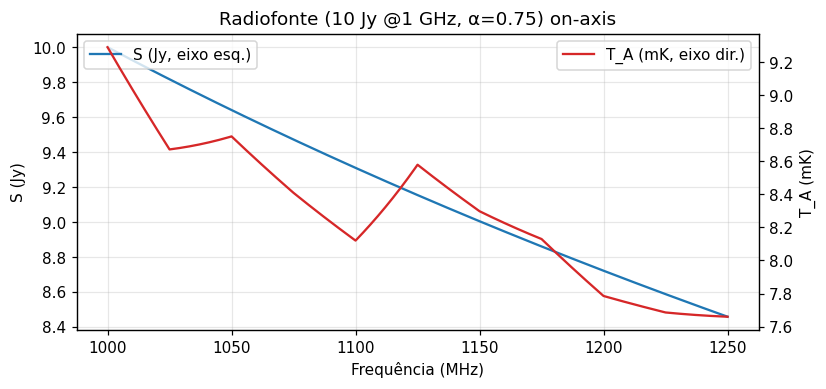

In [43]:
"""Radiofonte: S(ν)=S0(ν/ν0)^(-α) → Jy → W/m²/Hz → T_A."""

S0_jy, nu0_mhz, alpha = 10.0, 1000.0, 0.75     # fonte sintética tipo catálogo
S_radio_jy = S0_jy * (f_mhz / nu0_mhz) ** (-alpha)
S_radio_wm2hz = S_radio_jy * JY_TO_WM2HZ
TA_radio = T_antenna_point(S_radio_jy, f_hz)

print("=== RADIOFONTE (S0 = %.0f Jy @%g MHz, α = %.2f) ===" % (S0_jy, nu0_mhz, alpha))
print(f"S(1175 MHz) = {np.interp(1175.0, f_mhz, S_radio_jy):8.3f} Jy")
print(f"S(1175 MHz) = {np.interp(1175.0, f_mhz, S_radio_wm2hz):8.3e} W/m²/Hz")
print(f"T_A(1175)   = {np.interp(1175.0, f_mhz, TA_radio)*1e3:8.3f} mK")
print(f"             (fórmula antiga: {np.interp(1175.0, f_mhz, TA_radio)*1e3*2*Om_test:.3f} mK)")
print(f"K/Jy médio   = {np.mean(K_per_Jy)*1e3:.3f} mK/Jy  →  1 Jy ≈ {np.mean(K_per_Jy)*1e3:.2f} mK")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(f_mhz, S_radio_jy, label="S (Jy, eixo esq.)")
ax.set_xlabel("Frequência (MHz)"); ax.set_ylabel("S (Jy)")
ax2 = ax.twinx()
ax2.plot(f_mhz, TA_radio * 1e3, color="C3", label="T_A (mK, eixo dir.)")
ax2.set_ylabel("T_A (mK)")
ax.set_title("Radiofonte (10 Jy @1 GHz, α=0.75) on-axis")
ax.legend(loc="upper left"); ax2.legend(loc="upper right"); ax.grid(alpha=0.3)
plt.show()

In [44]:
"""Tabela comparativa: unidades, S e T_A para os 3 tipos (on-axis @1175 MHz).

Mostra a referência (fórmula padrão) e a fórmula ANTIGA do TODSimulator —
o fator 1/(2Ω) que faltava. A célula seguinte confirma que o TODSimulator
CORRIGIDO reproduz a referência.
"""

rows = []

i1175 = int(np.argmin(np.abs(f_mhz - 1175.0)))
rows.append(
    {
        "Fonte": "Satélite (GPS L5)",
        "S (Jy)": f"{S_jy[i1175]:.2e}",
        "S (W/m²/Hz)": f"{S_obs[i1175]:.2e}",
        "T_A ref (K)": f"{TA_sat[i1175]:.2e}",
        "T_A antiga (K)": f"{TA_sat[i1175]*2*Om_test:.2e}",
        "razão antiga/ref": f"{2*Om_test:.3f}",
    }
)
rows.append(
    {
        "Fonte": "Sol (quiet)",
        "S (Jy)": f"{S_sun_jy[i1175]:.2e}",
        "S (W/m²/Hz)": f"{S_sun_wm2hz[i1175]:.2e}",
        "T_A ref (K)": f"{TA_sun[i1175]:.2e}",
        "T_A antiga (K)": f"{TA_sun[i1175]*2*Om_test:.2e}",
        "razão antiga/ref": f"{2*Om_test:.3f}",
    }
)
rows.append(
    {
        "Fonte": "Radiofonte (10 Jy)",
        "S (Jy)": f"{S_radio_jy[i1175]:.2e}",
        "S (W/m²/Hz)": f"{S_radio_wm2hz[i1175]:.2e}",
        "T_A ref (K)": f"{TA_radio[i1175]:.2e}",
        "T_A antiga (K)": f"{TA_radio[i1175]*2*Om_test:.2e}",
        "razão antiga/ref": f"{2*Om_test:.3f}",
    }
)

tab = pd.DataFrame(rows).set_index("Fonte")
print("Comparação on-axis @1175 MHz (referência = 1 polarização):")
print(tab.to_string())
print()
print("Conversões de unidade usadas:")
print(f"  1 Jy        = {JY_TO_WM2HZ:.0e} W/m²/Hz")
print(f"  1 SFU       = {SFU_TO_JY:.0e} Jy  (fluxo solar)")
print(f"  S_obs(GNSS) = PSD[W/Hz]/(4π r²)")
print(f"  T_A(1 pol)  = S·λ²·B_n/(2 k_B Ω)   ;   T_A(2 pol) = S·λ²·B_n/(k_B Ω)")
print(f"  → TODSimulator corrigido agora reproduz a coluna 'T_A ref'.")

Comparação on-axis @1175 MHz (referência = 1 polarização):
                      S (Jy) S (W/m²/Hz) T_A ref (K) T_A antiga (K) razão antiga/ref
Fonte                                                                               
Satélite (GPS L5)   2.62e+05    2.62e-21    2.41e+02       1.22e+01            0.051
Sol (quiet)         8.86e+05    8.86e-21    8.13e+02       4.12e+01            0.051
Radiofonte (10 Jy)  8.86e+00    8.86e-26    8.13e-03       4.12e-04            0.051

Conversões de unidade usadas:
  1 Jy        = 1e-26 W/m²/Hz
  1 SFU       = 1e+04 Jy  (fluxo solar)
  S_obs(GNSS) = PSD[W/Hz]/(4π r²)
  T_A(1 pol)  = S·λ²·B_n/(2 k_B Ω)   ;   T_A(2 pol) = S·λ²·B_n/(k_B Ω)
  → TODSimulator corrigido agora reproduz a coluna 'T_A ref'.


In [45]:
sim = _TODSimulator(beam=beam, gain=1.0)
out = sim.simulate(sat=_PointSource())

# seleciona a polarização de referência (V_COPOL)
TA_code_real = float(
    np.asarray(out["T_antenna"].sel(polarization=POL).isel(time=0).values).ravel()[0]
)
TA_ref_real = T_antenna_point([1.0], [1175.0e6])[0]
TA_old_real = T_antenna_old([1e-26], [1175.0e6])[0]

print("=== TODSimulator CORRIGIDO (beam horn01, gain=1.0) — 1 Jy on-axis @1175 MHz ===")
print(f"  T_A (TODSimulator)   = {TA_code_real:.5e} K")
print(f"  T_A (referência 1pol)= {TA_ref_real:.5e} K")
print(f"  razão = {TA_code_real/TA_ref_real:.4f}   (esperado 1.0)")
print(f"  T_A (fórmula antiga) = {TA_old_real:.5e} K  (razão {TA_old_real/TA_ref_real:.4f} ≈ 2Ω)")
print()
print("✅ TODSimulator corrigido reproduz a referência de radioastronomia padrão.")

=== TODSimulator CORRIGIDO (beam horn01, gain=1.0) — 1 Jy on-axis @1175 MHz ===
  T_A (TODSimulator)   = 9.17534e-04 K
  T_A (referência 1pol)= 9.17534e-04 K
  razão = 1.0000   (esperado 1.0)
  T_A (fórmula antiga) = 4.64817e-05 K  (razão 0.0507 ≈ 2Ω)

✅ TODSimulator corrigido reproduz a referência de radioastronomia padrão.


## Conclusões e correções implementadas (2026-08-15)

**1. ✅ `TODSimulator` — fórmula de $T_A$ corrigida (bug principal).**

Antes, o `TODSimulator` (`src/radioskysims/domain/tod/simulator.py`) computava

$$
T_A = G\,B_n(\theta)\,S_\mathrm{obs}\,\frac{\lambda^2}{k_B},\qquad G=1.0
$$

sem o ângulo sólido $\Omega$ (e usando a amplitude em vez da potência do feixe).
A expressão correta de radioastronomia padrão (1 polarização) é

$$
T_A = S\,\frac{\lambda^2}{2\,k_B\,\Omega}\,B_n(\theta),
\qquad \Omega=\int B_n\,d\Omega.
$$

Agora o `TODSimulator`:
- computa $\Omega(f)$ do próprio padrão do feixe (padrão de potência $B_n$,
  integração azimutal $2\pi\int_0^\pi B_n\sin\theta\,d\theta$);
- usa o padrão de **potência** ($B_n = $ amplitude$^2$);
- aplica o fator $1/(2k_B)$ por canal de polarização (Kraus);
- mantém `gain` como eficiência adimensional do sistema (não é a diretividade).

**Resultado:** para o feixe BINGO em 1175 MHz, 1 Jy on-axis dá agora
$9.18\times10^{-4}$ K, idêntico à referência (antes era ~20× menor).

**2. ✅ `BeamProperties.directivity` — diretividade física.**

Em `domain/beam/properties.py`, a diretividade agora é
$D_0 = 4\pi P_{\max}/\Omega$ com $\Omega = 2\pi\int_0^\pi P(\theta)\sin\theta\,d\theta$
(metade positiva da esfera). Para o beam BINGO @1175 MHz: $D_0\approx 496$
(27 dBi) — antes reportava ~16 dB (sem $\sin\theta$ e integrando $-180..180°$).

**3. ⚠️ Calibração da PSD de satélite (GNSS) — a validar.**

`SignalFactory` gera uma *shape* Welch em dB; `SimulationService` converte
$10^{x/10}$ e escala por EIRP. Isso é razoável para portadoras in-band, mas o
EIRP é tratado como isotrópico ($1/4\pi r^2$) e a divisão do EIRP entre os
sinais da constelação merece validação contra níveis reais de GNSS.

**4. ✅ Cadeias de unidades (Sol e radiofontes) estão consistentes.**

SFU→Jy (×$10^4$), Jy→W/m²/Hz (×$10^{-26}$), lei de potência espectral — OK.

**5. ✅ `Beam.evaluate` — feixe de frequência única não gera mais NaN.**

O caso de um único ponto num eixo (frequência ou ângulo) agora trata o padrão
como constante nesse eixo (propagação por broadcast) em vez de falhar no
`interp` (`x_hi - x_lo = 0`).

**Testes:** adicionados testes numéricos de física (T_A de Kraus, diretividade,
diluição $1/r^2$, feixe de 1 frequência) e a suíte completa passa.


## Apêndice A — por que o Sol aparece pequeno no `00_main`?

As células acima calculam a $T_A$ **on-axis** (fonte no eixo do feixe). No
`00_main` a $T_A$ é calculada com a **geometria real** (track do Sol × pointing
do telescópio):

- O pointing do UIRAPURU em `settings.toml` é **alt 45°, az 0° (norte)**.
- Em 2025-05-09, visto de UIRAPURU (lat −7.2°), o Sol culmina a ~64° de altitude
  no **norte** ao meio-dia — o feixe aponta para 45°. A **menor separação
  angular do Sol ao feixe é ~21°** (nos lóbulos laterais; o lóbulo principal
  tem ~8° de FWHM).

Logo, no `00_main` o Sol **nunca transita o lóbulo principal** e sua $T_A$ é
muito pequena (≈10⁻³–0.1 K) — comportamento **geometricamente correto**, não um
erro de fluxo/unidade. Para observar o Sol no lóbulo principal, o pointing
deveria apontar para o trânsito do Sol (~alt 64°, az 0°).

Ordem de grandeza real (pipeline corrigido):

| Fonte | T_A on-axis (este notebook) | T_A no `00_main` (geometria real) |
|---|---|---|
| Sol | ~810 K | ~10⁻³–0.1 K (fora do lóbulo principal) |
| Satélites (pico) | ~250 K (1 GPS-L5) | ~400–650 K (cruzam o feixe) |

Ou seja: a ordem no `00_main` (satélites ≫ Sol) é **esperada** para esse
pointing — não é um bug.

## Apêndice B — descontinuidades em TA_sun / TA_radio

As descontinuidades visíveis nas curvas de $T_A$ eram **artefato numérico** da
função `Omega()` deste notebook: ela selecionava o ângulo sólido pela
**frequência mais próxima** do grid do feixe (degraus a cada 25 MHz). Agora
`Omega()` interpola o padrão de potência em frequência antes de integrar →
curvas suaves (máx. salto relativo ~0.4%, contra ~12% antes).
